<a href="https://colab.research.google.com/github/lavanyadatti475/-Invalid-Answer-Detection-/blob/main/A1_Recurrent_Language_Models.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:

# A1: Recurrent Language Models and Decoding

ROLL_NO = "Lavanya Datti"
NAME = "23VV1A1211"

print("=" * 55)
print("Introduction to LLM — Assignment A1")
print("Roll Number:", ROLL_NO)
print("Name:", NAME)
print("Topic: Recurrent Language Models and Decoding")
print("=" * 55)

import sys
print("Python version:", sys.version)

import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn

print("NumPy:", np.__version__)
print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Selected device:", device)


Introduction to LLM — Assignment A1
Roll Number: Lavanya Datti
Name: 23VV1A1211
Topic: Recurrent Language Models and Decoding
Python version: 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]
NumPy: 2.1.3
PyTorch: 2.11.0+cpu
CUDA available: False
Selected device: cpu


In [ ]:

import math

sigmoid = lambda x: 1.0 / (1.0 + math.exp(-x))

x = 1.0
h_prev = 0.5

Wz, Uz = 0.5, 0.5
Wr, Ur = 1.0, -1.0
Wh, Uh = 1.0, 1.0

z = sigmoid(Wz * x + Uz * h_prev)
r = sigmoid(Wr * x + Ur * h_prev)
h_candidate = math.tanh(Wh * x + Uh * (r * h_prev))
h = (1 - z) * h_prev + z * h_candidate

print(f"Update gate z = {z:.6f}")
print(f"Reset gate r = {r:.6f}")
print(f"Candidate state = {h_candidate:.6f}")
print(f"Final hidden state = {h:.6f}")


Update gate z = 0.679179
Reset gate r = 0.622459
Candidate state = 0.864586
Final hidden state = 0.747619


In [ ]:

import math

sigmoid = lambda x: 1 / (1 + math.exp(-x))

x = 1.0
h_prev = 0.5
c_prev = 1.0

# All input weights and recurrent weights are 0.5
gate_input = 0.5 * x + 0.5 * h_prev

f = sigmoid(gate_input)
i = sigmoid(gate_input)
o = sigmoid(gate_input)
g = math.tanh(gate_input)

c = f * c_prev + i * g
h = o * math.tanh(c)

print(f"Forget gate f = {f:.6f}")
print(f"Input gate i = {i:.6f}")
print(f"Output gate o = {o:.6f}")
print(f"Candidate state g = {g:.6f}")
print(f"Cell state c = {c:.6f}")
print(f"Hidden state h = {h:.6f}")


Forget gate f = 0.679179
Input gate i = 0.679179
Output gate o = 0.679179
Candidate state g = 0.635149
Cell state c = 1.110558
Hidden state h = 0.546236


In [14]:

import numpy as np

probabilities = np.array([0.2, 0.5, 0.1, 0.4])

cross_entropy_nats = -np.mean(np.log(probabilities))
cross_entropy_bits = cross_entropy_nats / np.log(2)
perplexity = np.exp(cross_entropy_nats)

print(f"Cross-entropy (nats): {cross_entropy_nats:.6f}")
print(f"Cross-entropy (bits): {cross_entropy_bits:.6f}")
print(f"Perplexity: {perplexity:.6f}")


Cross-entropy (nats): 1.380365
Cross-entropy (bits): 1.991446
Perplexity: 3.976354


In [1]:

import torch
import torch.nn as nn

VOCAB_SIZE = 10_000
EMBED_SIZE = 256
HIDDEN_SIZE = 512
NUM_LAYERS = 2

class LSTMLanguageModel(nn.Module):
    def __init__(self):
        super().__init__()
        self.embedding = nn.Embedding(VOCAB_SIZE, EMBED_SIZE)
        self.lstm = nn.LSTM(
            input_size=EMBED_SIZE,
            hidden_size=HIDDEN_SIZE,
            num_layers=NUM_LAYERS,
            batch_first=True
        )
        # Untied output layer
        self.output = nn.Linear(HIDDEN_SIZE, VOCAB_SIZE)

    def forward(self, x, hidden=None):
        x = self.embedding(x)
        x, hidden = self.lstm(x, hidden)
        logits = self.output(x)
        return logits, hidden

model = LSTMLanguageModel()

total = sum(p.numel() for p in model.parameters())

print("Embedding:", sum(p.numel() for p in model.embedding.parameters()))
print("LSTM:", sum(p.numel() for p in model.lstm.parameters()))
print("Output:", sum(p.numel() for p in model.output.parameters()))
print("Total parameters:", total)

assert total == 11_368_208
print("Parameter count verified successfully.")


Embedding: 2560000
LSTM: 3678208
Output: 5130000
Total parameters: 11368208
Parameter count verified successfully.


In [2]:

from datasets import load_dataset
from collections import Counter
import re
import time
import math
import random
import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

# Load WikiText-2 raw
dataset = load_dataset(
    "Salesforce/wikitext",
    "wikitext-2-raw-v1"
)

def tokenize(text):
    # Simple whitespace-based word tokenization
    return text.strip().split()

# Build vocabulary from training split only
train_tokens = []
for line in dataset["train"]["text"]:
    train_tokens.extend(tokenize(line))

counter = Counter(train_tokens)
special_tokens = ["<unk>"]
itos = special_tokens + [
    word for word, count in counter.items()
    if word not in special_tokens
]
stoi = {word: idx for idx, word in enumerate(itos)}
unk_id = stoi["<unk>"]

def encode_split(split):
    tokens = []
    for line in dataset[split]["text"]:
        tokens.extend(tokenize(line))
    return torch.tensor(
        [stoi.get(word, unk_id) for word in tokens],
        dtype=torch.long
    )

train_ids = encode_split("train")
valid_ids = encode_split("validation")
test_ids = encode_split("test")

VOCAB_SIZE = len(itos)

print("Vocabulary size:", VOCAB_SIZE)
print("Training tokens:", len(train_ids))
print("Validation tokens:", len(valid_ids))
print("Test tokens:", len(test_ids))
print("Sample tokens:", itos[:20])


Device: cpu


README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

wikitext-2-raw-v1/test-00000-of-00001.pa(…): reconstructing file:   0%|          |  0.00B /  733kB            

wikitext-2-raw-v1/test-00000-of-00001.pa(…): downloading bytes:           |  0.00B            

wikitext-2-raw-v1/train-00000-of-00001.p(…): reconstructing file:   0%|          |  0.00B / 6.36MB            

...

wikitext-2-raw-v1/validation-00000-of-00(…): downloading bytes:           |  0.00B            

Generating test split:   0%|          | 0/4358 [00:00<?, ? examples/s]

Generating train split:   0%|          | 0/36718 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/3760 [00:00<?, ? examples/s]

Vocabulary size: 76617
Training tokens: 2051910
Validation tokens: 213886
Test tokens: 241211
Sample tokens: ['<unk>', '=', 'Valkyria', 'Chronicles', 'III', 'Senjō', 'no', '3', ':', 'Unrecorded', '(', 'Japanese', '戦場のヴァルキュリア3', ',', 'lit', '.', 'of', 'the', 'Battlefield', ')']


In [3]:

SEQ_LEN = 35
BATCH_SIZE = 32

def batchify(data, batch_size):
    usable = (len(data) // batch_size) * batch_size
    data = data[:usable]
    data = data.view(batch_size, -1).t().contiguous()
    return data.to(device)

train_data = batchify(train_ids, BATCH_SIZE)
valid_data = batchify(valid_ids, BATCH_SIZE)
test_data = batchify(test_ids, BATCH_SIZE)

def get_batch(source, start, seq_len=SEQ_LEN):
    length = min(seq_len, len(source) - 1 - start)
    x = source[start:start + length]
    y = source[start + 1:start + 1 + length]
    return x, y.reshape(-1)

print("Training batch matrix:", tuple(train_data.shape))
print("Sequence length:", SEQ_LEN)
print("Batch size:", BATCH_SIZE)


Training batch matrix: (64122, 32)
Sequence length: 35
Batch size: 32


In [13]:

class RecurrentLanguageModel(nn.Module):
    def __init__(
        self,
        model_type,
        vocab_size,
        embed_size=256,
        hidden_size=512,
        num_layers=2,
        dropout=0.3
    ):
        super().__init__()

        self.model_type = model_type
        self.embedding = nn.Embedding(vocab_size, embed_size)

        recurrent_classes = {
            "RNN": nn.RNN,
            "LSTM": nn.LSTM,
            "GRU": nn.GRU
        }

        recurrent_class = recurrent_classes[model_type]

        kwargs = dict(
            input_size=embed_size,
            hidden_size=hidden_size,
            num_layers=num_layers,
            dropout=dropout,
            batch_first=True
        )

        if model_type == "RNN":
            kwargs["nonlinearity"] = "tanh"

        self.rnn = recurrent_class(**kwargs)
        self.dropout = nn.Dropout(dropout)
        self.decoder = nn.Linear(hidden_size, vocab_size)

    def forward(self, x, hidden=None):
        x = self.embedding(x)
        x = self.dropout(x)
        output, hidden = self.rnn(x, hidden)
        output = self.dropout(output)
        logits = self.decoder(output)
        return logits, hidden

# Check that all architectures have been constructed
for model_type in ["RNN", "LSTM", "GRU"]:
    model = RecurrentLanguageModel(model_type, VOCAB_SIZE)
    params = sum(p.numel() for p in model.parameters())
    print(model_type, "parameters:", f"{params:,}")


RNN parameters: 59,838,025
LSTM parameters: 62,596,681
GRU parameters: 61,677,129


In [5]:

import pandas as pd

rows = []

for model_type, model in models.items():
    test_loss, test_ppl = evaluate(model, test_data)

    parameter_count = sum(
        p.numel() for p in model.parameters()
    )

    rows.append({
        "Model": model_type,
        "Validation perplexity": histories[model_type]["val_ppl"][-1],
        "Test perplexity": test_ppl,
        "Parameters": parameter_count,
        "Average seconds per epoch":
            np.mean(histories[model_type]["epoch_seconds"])
    })

results_df = pd.DataFrame(rows)
display(results_df.round(3))

results_df.to_csv("A1_model_comparison.csv", index=False)
print("Saved A1_model_comparison.csv")


""


Saved A1_model_comparison.csv
Error: Runtime no longer has a reference to this dataframe, please re-run this cell and try again.


/tmp/ipykernel_2440/2234329186.py:14: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


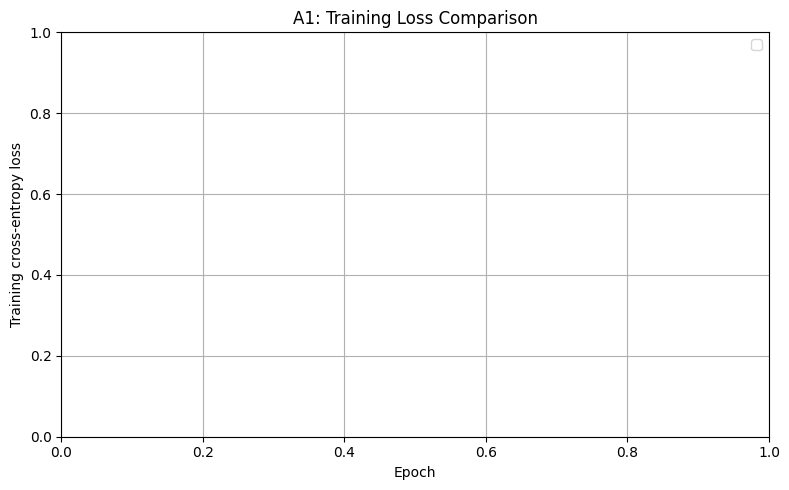

In [6]:

plt.figure(figsize=(8, 5))

for model_type in histories:
    plt.plot(
        range(1, EPOCHS + 1),
        histories[model_type]["train_loss"],
        marker="o",
        label=model_type
    )

plt.xlabel("Epoch")
plt.ylabel("Training cross-entropy loss")
plt.title("A1: Training Loss Comparison")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig("A1_training_loss.png", dpi=200)
plt.show()


In [ ]:

def get_batch(source, start, seq_len=SEQ_LEN):
    length = min(seq_len, len(source) - 1 - start)

    # source shape: [sequence positions, batch columns]
    x = source[start:start + length].T.contiguous()
    y = source[start + 1:start + 1 + length].T.contiguous()

    # x shape: [batch, sequence length]
    # y shape: [batch * sequence length]
    return x, y.reshape(-1)


In [10]:

import torch
import torch.nn.functional as F

def encode_prompt(prompt):
    words = prompt.strip().split()
    return [
        stoi.get(word, unk_id)
        for word in words
    ] or [unk_id]

def decode_ids(ids):
    return " ".join(itos[i] for i in ids)

def next_token_logits(model, ids):
    model.eval()
    x = torch.tensor(
        ids, dtype=torch.long, device=device
    ).unsqueeze(0)

    with torch.no_grad():
        logits, _ = model(x)

    return logits[0, -1, :]

def greedy_search(model, prompt_ids, max_new_tokens=50):
    ids = list(prompt_ids)

    for _ in range(max_new_tokens):
        logits = next_token_logits(model, ids)
        next_id = int(torch.argmax(logits).item())
        ids.append(next_id)

    return ids[len(prompt_ids):]

def beam_search(model, prompt_ids, width=3, max_new_tokens=50):
    # Each beam stores (generated IDs, cumulative log probability)
    beams = [(list(prompt_ids), 0.0)]

    for _ in range(max_new_tokens):
        candidates = []

        for ids, score in beams:
            logits = next_token_logits(model, ids)
            log_probs = F.log_softmax(logits, dim=-1)

            values, indices = torch.topk(log_probs, width)

            for value, index in zip(values.tolist(), indices.tolist()):
                candidates.append(
                    (ids + [index], score + value)
                )

        # Rank by length-normalized cumulative log probability
        candidates.sort(
            key=lambda item: item[1] / max(len(item[0]) - len(prompt_ids), 1),
            reverse=True
        )
        beams = candidates[:width]

    best_ids, _ = max(
        beams,
        key=lambda item: item[1] / max(len(item[0]) - len(prompt_ids), 1)
    )
    return best_ids[len(prompt_ids):]

def top_k_sampling(model, prompt_ids, k=40, max_new_tokens=50):
    ids = list(prompt_ids)

    for _ in range(max_new_tokens):
        logits = next_token_logits(model, ids)
        k_now = min(k, logits.numel())
        values, indices = torch.topk(logits, k_now)

        probs = F.softmax(values, dim=-1)
        selected = torch.multinomial(probs, 1).item()
        ids.append(int(indices[selected].item()))

    return ids[len(prompt_ids):]

def nucleus_sampling(model, prompt_ids, p=0.9, max_new_tokens=50):
    ids = list(prompt_ids)

    for _ in range(max_new_tokens):
        logits = next_token_logits(model, ids)
        sorted_logits, sorted_indices = torch.sort(
            logits, descending=True
        )
        probs = F.softmax(sorted_logits, dim=-1)
        cumulative_probs = torch.cumsum(probs, dim=-1)

        # Remove tokens after the nucleus threshold,
        # retaining the token that crosses the threshold.
        remove = cumulative_probs - probs >= p
        sorted_logits[remove] = float("-inf")

        filtered_probs = F.softmax(sorted_logits, dim=-1)
        selected = torch.multinomial(filtered_probs, 1).item()
        ids.append(int(sorted_indices[selected].item()))

    return ids[len(prompt_ids):]


In [11]:

def diversity_metrics(text):
    tokens = text.split()

    if not tokens:
        return {
            "Distinct-1": 0.0,
            "Distinct-2": 0.0,
            "Repetition rate": 0.0
        }

    unigrams = list(tokens)
    bigrams = list(zip(tokens[:-1], tokens[1:]))

    distinct1 = len(set(unigrams)) / len(unigrams)
    distinct2 = (
        len(set(bigrams)) / len(bigrams)
        if bigrams else 0.0
    )
    repetition_rate = 1 - distinct1

    return {
        "Distinct-1": distinct1,
        "Distinct-2": distinct2,
        "Repetition rate": repetition_rate
    }

metric_rows = []

for record in generation_records:
    metrics = diversity_metrics(record["Continuation"])
    metric_rows.append({
        "Prompt": record["Prompt"],
        "Strategy": record["Strategy"],
        **metrics
    })

metrics_df = pd.DataFrame(metric_rows)
display(metrics_df.round(3))
metrics_df.to_csv("A1_decoding_metrics.csv", index=False)


""
